# Predicting the winner at different stages of the game using Decision Trees

## Question: 
Can we predict the winner of a game at different stages using Decision Trees? These stages include before the game starts, after 10 moves, 20 moves, etc.

## Analysis Plan:
1. Load the dataset and perform initial exploration.
2. Train the Decision Tree model on the available features.
3. Evaluate the model's performance using accuracy, confusion matrix, and classification report.
4. Repeat the step for different stages of the game to see how the model's performance changes.
5. Visualize the difference between the stages

In [148]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_recall_curve,
    average_precision_score,
    ConfusionMatrixDisplay, 
    PrecisionRecallDisplay
)


Firstly, lets load the dataset

In [149]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)

print(data["winner"].value_counts())
print(data["winner"].value_counts(normalize=True) * 100)

winner
white    10001
black     9107
draw       950
Name: count, dtype: int64
winner
white    49.860405
black    45.403330
draw      4.736265
Name: proportion, dtype: float64


## Selecting our initial features and target variable
We will start by selecting the features that are available before the game starts. These features include: 
- Player 1's rating
- Player 2's rating
- The opening plies

We can also include some features based on rating differences, to see how they compare to the individual ratings.

In [150]:
data = data[data["winner"] != "draw"]  # Filter out draws

data["rating_diff"] = data["white_rating"] - data["black_rating"]
data["rating_difference_abs"] = data["rating_diff"].abs()
data["rating_average"] = (data["white_rating"] + data["black_rating"]) / 2

features = ["white_rating", "black_rating", "rating_diff", "opening_ply", "rating_difference_abs", "rating_average"]

X = data[features]

y = data["winner"].map({"white": 1, "black": -1}) 

## Split the dataset
Separate your dataset into training and testing data. We will use 80% of the data for training and 20% for testing. This will allow us to evaluate the model's performance on unseen data.

In [151]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

We can now create our first Decision Tree model using the training data. After training, we will evaluate the model's performance on the test data.

In [152]:
from sklearn.model_selection import GridSearchCV


grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {
        "max_depth": range(2,10),
        "min_samples_leaf": [1, 2, 4],
    },
    cv=5,
    scoring='f1',
)


grid.fit(X_train, y_train)
model = grid.best_estimator_
print("Best parameters:", grid.best_params_)

Best parameters: {'max_depth': 3, 'min_samples_leaf': 1}


## Evaluate the model's performance
Let's evaluate the model's performance using accuracy, confusion matrix, and classification report. This will give us insights into how well the model is performing and where it might be making mistakes.

As we can see, the model's accuracy is at around 64%. This is a good starting point, but lets see if we can improve the model's performance by now looking at the further stages of the game. We will now look at the model's performance after 10 moves, 20 moves, and so on.

Accuracy: 0.652014652014652
Macro F1: 0.6453483780349663
              precision    recall  f1-score   support

          -1       0.67      0.54      0.60      1822
           1       0.64      0.75      0.69      2000

    accuracy                           0.65      3822
   macro avg       0.65      0.65      0.65      3822
weighted avg       0.65      0.65      0.65      3822

Confusion Matrix:
 [[ 984  838]
 [ 492 1508]]


Text(0.5, 1.0, 'Precision-Recall Curve')

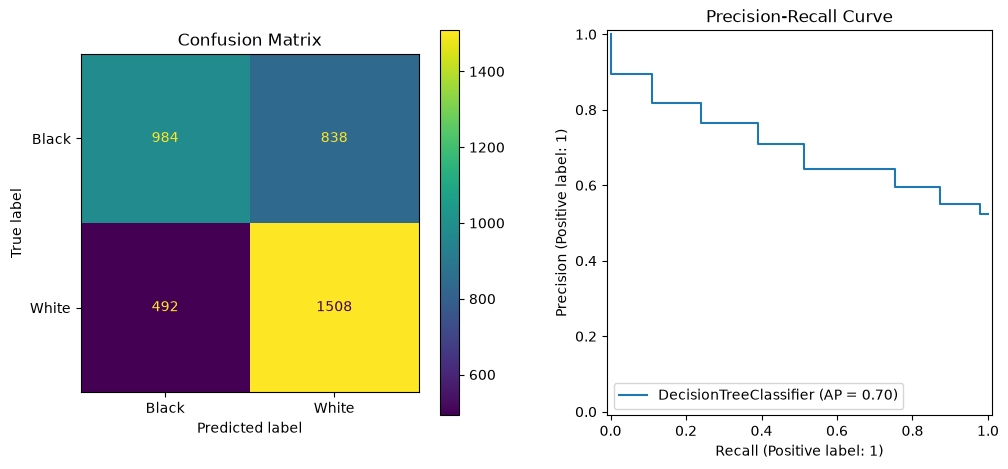

In [153]:


predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
macro_f1 = f1_score(y_test, predictions, average="macro")
conf_matrix = confusion_matrix(y_test, predictions)

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print(classification_report(y_test, predictions))
print("Confusion Matrix:\n", conf_matrix)

results = [{
    "moves": "Start",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "confusion_matrix": conf_matrix
}]

# Plot both on the same figure
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["Black", "White"], ax=ax[0])
ax[0].set_title("Confusion Matrix")
PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=ax[1])
ax[1].set_title("Precision-Recall Curve")

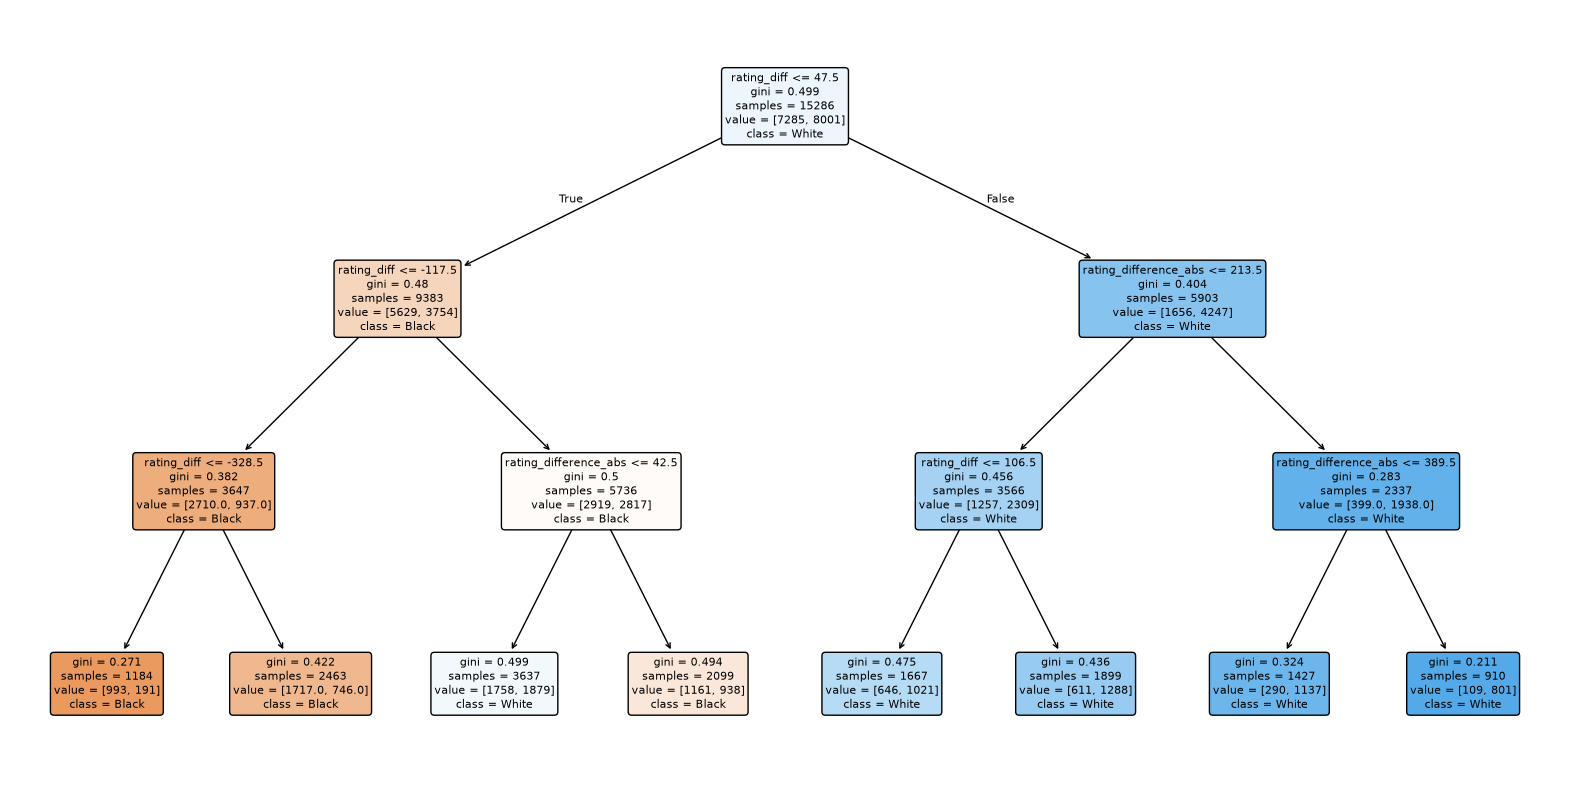

In [154]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=["Black", "White"],
    filled=True,
    rounded=True
)

plt.show()

In [155]:
def whites_move(i):
    return i % 2 == 0

"""
Extracts move information from a list of moves.
Calculates the number of captures, checks, promotions, and castling for both white and black players.
"""
def extract_move_information(moves, move_cutoff):
    if move_cutoff == "Start":
        return {
            "white_captures": 0,
            "black_captures": 0,
            "white_checks": 0,
            "black_checks": 0,
            "white_promotions": 0,
            "black_promotions": 0,
            "white_castled": 0,
            "black_castled": 0,
        }
    # Take first `move_cutoff` moves from the moves string
    move_list = moves.split() if move_cutoff is None else moves.split()[:move_cutoff]

    features = {
        "white_captures": 0,
        "black_captures": 0,
        "white_checks": 0,
        "black_checks": 0,
        "white_promotions": 0,
        "black_promotions": 0,
        "white_castled": 0,
        "black_castled": 0,
    }

    
    for i, move in enumerate(move_list):
        # Capture
        if "x" in move:
            if whites_move(i):  # White's move
                features["white_captures"] += 1
            else:  # Black's move
                features["black_captures"] += 1
        # Check
        if "+" in move:
            if whites_move(i):
                features["white_checks"] += 1
            else:  # Black's move
                features["black_checks"] += 1
        # Promotion
        if "=" in move:
            if whites_move(i):
                features["white_promotions"] += 1
            else:  # Black's move
                features["black_promotions"] += 1
        # Castled
        if "O-O" in move or "O-O-O" in move:
            if whites_move(i):
                features["white_castled"] = 1
            else:  # Black's move
                features["black_castled"] = 1
    return features

In [163]:

def decision_tree_model_after_N_moves(data_after_N_moves, y, model_class, perform_grid_search=True):
    X_train, X_test, y_train, y_test = train_test_split(data_after_N_moves, y, test_size=0.2, random_state=42, stratify=y)

    grid = GridSearchCV(
        model_class(random_state=42),
        {
            "max_depth": range(2,10),
            "min_samples_leaf": [1, 2, 4],
        },
        cv=5,
        scoring='f1',
    )
    if perform_grid_search:
        grid.fit(X_train, y_train)
        model = grid.best_estimator_
    else:
        model = model_class(random_state=42)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average="macro")
    confusion = confusion_matrix(y_test, predictions)
    return accuracy, f1, confusion

In [157]:
steps = [10, 20, 40, 60, 80, None]  # None is a placeholder for all moves

for step in steps:
    data_after_x_moves = data.copy()

    addtional_features = pd.DataFrame(
        data_after_x_moves["moves"].apply(lambda x: extract_move_information(x, step))
        .tolist(), index=data_after_x_moves.index
    )
    y = data_after_x_moves["winner"].map({"white": 1, "black": -1})
    data_after_x_moves = pd.concat([data_after_x_moves[features], addtional_features], axis=1)

    accuracy, f1, conf_matrix = decision_tree_model_after_N_moves(
        data_after_x_moves, y, DecisionTreeClassifier
    )   

    results.append({
        "moves": "All" if step == None else step,
        "accuracy": accuracy,
        "macro_f1": f1,
        "confusion_matrix": conf_matrix
    })

results_df = pd.DataFrame(results)

print(results_df)


   moves  accuracy  macro_f1            confusion_matrix
0  Start  0.652015  0.645348   [[984, 838], [492, 1508]]
1     10  0.652015  0.645348   [[984, 838], [492, 1508]]
2     20  0.652015  0.645348   [[984, 838], [492, 1508]]
3     40  0.692046  0.689487  [[1149, 673], [504, 1496]]
4     60  0.739927  0.738563  [[1276, 546], [448, 1552]]
5     80  0.764260  0.762960  [[1319, 503], [398, 1602]]
6    All  0.796703  0.796105  [[1419, 403], [374, 1626]]


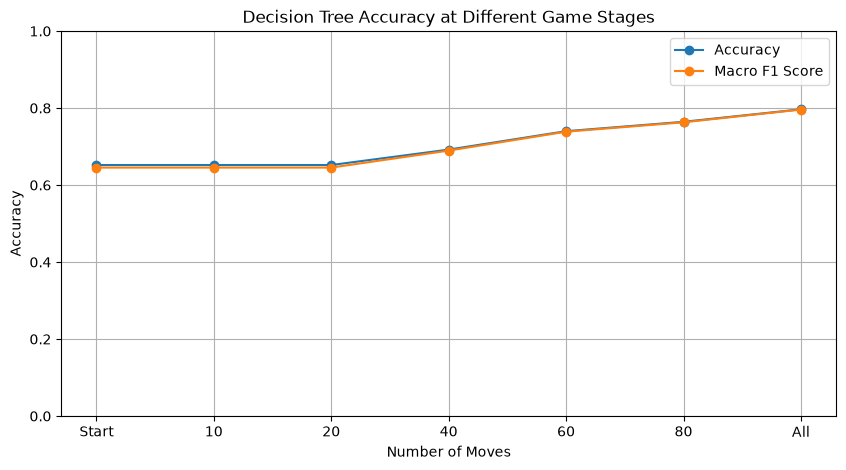

In [158]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["moves"].astype(str),
    results_df["accuracy"],
    marker="o",
    label="Accuracy"
)
plt.plot(
    results_df["moves"].astype(str),
    results_df["macro_f1"],
    marker="o",
    label="Macro F1 Score"
)
plt.title("Decision Tree Accuracy at Different Game Stages")
plt.xlabel("Number of Moves")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.show()


Lets uh try a random forest now ig bruh. 

In [164]:
results_forest = []
steps = ["Start", 10, 20, 40, 60, 80, None]  # None is a placeholder for all moves

for step in steps:
    data_after_x_moves = data.copy()

    addtional_features = pd.DataFrame(
        data_after_x_moves["moves"].apply(lambda x: extract_move_information(x, step))
        .tolist(), index=data_after_x_moves.index
    )
    y = data_after_x_moves["winner"].map({"white": 1, "black": -1})
    data_after_x_moves = pd.concat([data_after_x_moves[features], addtional_features], axis=1)

    accuracy, f1, conf_matrix = decision_tree_model_after_N_moves(
        data_after_x_moves, y, RandomForestClassifier, perform_grid_search=False
    )   

    results_forest.append({
        "moves": "All" if step == None else step,
        "accuracy": accuracy,
        "macro_f1": f1,
        "confusion_matrix": conf_matrix
    })

results_df_forest = pd.DataFrame(results_forest)

print(results_df_forest)

   moves  accuracy  macro_f1            confusion_matrix
0  Start  0.636316  0.635434  [[1122, 700], [690, 1310]]
1     10  0.653846  0.653102  [[1161, 661], [662, 1338]]
2     20  0.668237  0.667654  [[1197, 625], [643, 1357]]
3     40  0.725275  0.724459  [[1282, 540], [510, 1490]]
4     60  0.773679  0.772947  [[1370, 452], [413, 1587]]
5     80  0.795395  0.794909  [[1427, 395], [387, 1613]]
6    All  0.828885  0.828387  [[1481, 341], [313, 1687]]


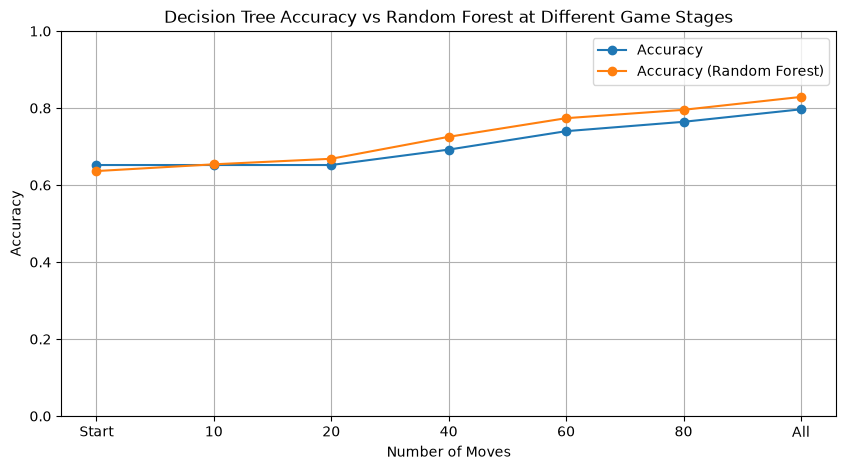

In [165]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["moves"].astype(str),
    results_df["accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df_forest["moves"].astype(str),
    results_df_forest["accuracy"],
    marker="o",
    label="Accuracy (Random Forest)"
)


plt.title("Decision Tree Accuracy vs Random Forest at Different Game Stages")
plt.xlabel("Number of Moves")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.show()